## 1. Загрузка данных

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
import h3

ROOT = Path.cwd()
if not (ROOT / "data/trips.parquet").exists():
    ROOT = ROOT / "seminars/assets/week02-geo"
sys.path.insert(0, str(ROOT))
from common import geojson_cells, hex_map, endpoint_events, event_balance, distance_km

sns.set_theme(style="whitegrid", palette="colorblind")
pio.renderers.default = "plotly_mimetype"
raw = pd.read_parquet(ROOT / "data/trips.parquet")
raw.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,started_at_raw,ended_at_raw,duration_min,day_type,hour,date,distance_km
0,3AAD1E1BCB6B326B,electric_bike,2025-09-04 08:36:52.378,2025-09-04 08:47:21.064,Lincoln Park,JC053,Dey St,JC065,40.724605,-74.078406,40.737711,-74.066921,casual,2025-09-04 08:36:52.378,2025-09-04 08:47:21.064,10.478100,Будни,8,2025-09-04,1.749363
1,EC348BE3649505F6,electric_bike,2025-09-08 18:00:44.089,2025-09-08 18:18:48.698,Exchange Pl,JC116,Dey St,JC065,40.716366,-74.034344,40.737711,-74.066921,member,2025-09-08 18:00:44.089,2025-09-08 18:18:48.698,18.076817,Будни,18,2025-09-08,3.628940
2,6639ACBA00F4DC07,classic_bike,2025-09-06 08:59:06.165,2025-09-06 14:27:30.692,Union St & Bergen Ave,JC122,Dey St,JC065,40.715750,-74.078870,40.737711,-74.066921,member,2025-09-06 08:59:06.165,2025-09-06 14:27:30.692,328.408783,Выходные,8,2025-09-06,2.641402
3,A10A50B94E43F61E,classic_bike,2025-09-08 18:11:33.185,2025-09-08 18:17:06.671,Bergen Ave & Sip Ave,JC109,Dey St,JC065,40.731009,-74.064437,40.737711,-74.066921,member,2025-09-08 18:11:33.185,2025-09-08 18:17:06.671,5.558100,Будни,18,2025-09-08,0.774074
4,56D1E808E38A2034,electric_bike,2025-09-24 17:39:37.945,2025-09-24 18:01:08.535,Exchange Pl,JC116,Dey St,JC065,40.716366,-74.034344,40.737711,-74.066921,member,2025-09-24 17:39:37.945,2025-09-24 18:01:08.535,21.509833,Будни,17,2025-09-24,3.628940


## 2. Структура таблицы

In [2]:
display(raw.shape)
display(raw.dtypes.to_frame("dtype"))
display(raw.nunique(dropna=False).to_frame("unique"))
display(raw.ride_id.duplicated().sum())

(116071, 20)

,dtype
ride_id,str
rideable_type,str
started_at,datetime64[us]
ended_at,datetime64[us]
start_station_name,str
start_station_id,string
end_station_name,str
end_station_id,string
start_lat,float64
start_lng,float64


,unique
ride_id,116071
rideable_type,2
started_at,116070
ended_at,115970
start_station_name,94
start_station_id,94
end_station_name,238
end_station_id,238
start_lat,94
start_lng,94


np.int64(0)

## 3. Период наблюдения

,ride_id,started_at,ended_at
7935,5E920CA9DAE1B366,2025-08-31 23:59:31.309,2025-09-01 00:09:08.045
28306,F234B95B89253838,2025-08-31 23:41:09.118,2025-09-01 00:25:23.589
30735,EBECD6C5FE914920,2025-08-31 19:53:37.526,2025-09-01 09:05:25.635
38153,F6122F0101A070FB,2025-08-31 23:42:48.090,2025-09-01 00:04:19.676
50200,EEFDD2BC93ABA0C3,2025-08-31 23:58:46.308,2025-09-01 00:53:16.977
60965,80BCEA053EF2FB4D,2025-08-31 12:01:56.126,2025-09-01 08:03:05.568
66176,32308ACA75958D53,2025-08-31 23:58:49.486,2025-09-01 00:06:59.093
67574,0EACA9FB9491C1C3,2025-08-31 23:57:41.610,2025-09-01 00:05:38.990
67575,CE4D03CD88A71F71,2025-08-31 23:57:39.593,2025-09-01 00:05:27.007
83404,EB8072EBBA061F75,2025-08-31 23:09:42.195,2025-09-01 00:02:27.241


,trips
date,
2025-09-01,2953
2025-09-02,3490
2025-09-03,3917
2025-09-04,3815
2025-09-05,4289
2025-09-06,3269
2025-09-07,2417
2025-09-08,3782
2025-09-09,3930


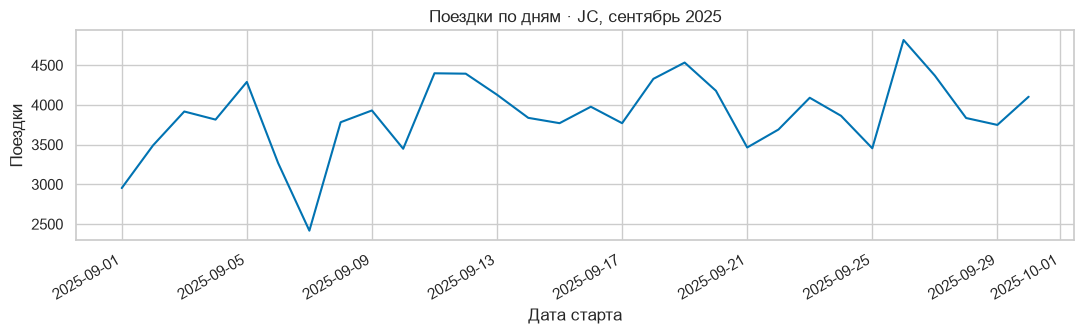

In [3]:
start = pd.Timestamp("2025-09-01")
stop = pd.Timestamp("2025-10-01")
in_month = raw.started_at.ge(start) & raw.started_at.lt(stop)
display(raw.loc[~in_month, ["ride_id", "started_at", "ended_at"]])
df = raw.loc[in_month].copy()
calendar = pd.DataFrame({"date": pd.date_range(start, stop, inclusive="left")})
calendar["day_type"] = np.where(calendar.date.dt.dayofweek < 5, "Будни", "Выходные")
daily = (df.groupby("date").size().reindex(calendar.date, fill_value=0).rename("trips"))
display(daily.to_frame())
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily.index, daily.values)
ax.set(xlabel="Дата старта", ylabel="Поездки", title="Поездки по дням · JC, сентябрь 2025")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 4. Пропуски

In [4]:
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
display(df.groupby("member_casual").end_lat.agg(rows="size", known="count"))
missing_end = df.end_lat.isna() | df.end_lng.isna()
display(pd.crosstab(df.member_casual, missing_end, normalize="index"))
display(df.loc[missing_end, ["ride_id", "start_station_name", "end_station_name", "duration_min"]].head())

,missing
end_lat,487
end_station_id,487
end_lng,487
distance_km,487
end_station_name,361
start_station_name,0
start_station_id,0
ended_at,0
start_lat,0
start_lng,0


,rows,known
member_casual,,
casual,28291,28085
member,87764,87483


col_0,False,True
member_casual,,
casual,0.992719,0.007281
member,0.996798,0.003202


,ride_id,start_station_name,end_station_name,duration_min
145,E603741D8F3484B9,11 St & Washington St,Stevens - River Ter & 6 St,8.322583
307,C050C06DD589E85B,14 St Ferry - 14 St & Shipyard Ln,South Waterfront Walkway - Sinatra Dr & 1 St,6.798133
362,06925011F37BCEA1,Lincoln Park,Stevens - River Ter & 6 St,20.417400
363,52030B0B8C6D49D3,River St & Newark St,Stevens - River Ter & 6 St,20.612233
364,91F8374517D8C5DA,Brunswick St,Stevens - River Ter & 6 St,14.876217


## 5. Распределение длительности

count    116055.000000
mean         10.744147
std          40.678685
min           1.006567
1%            1.430895
50%           6.471567
95%          25.670833
99%          62.069104
max        1499.948283
Name: duration_min, dtype: float64

,ride_id,started_at,ended_at,duration_min
37681,2F8210E664473584,2025-09-26 08:56:13.236,2025-09-27 09:12:07.942,1455.911767
76663,DCC96D06D76B302F,2025-09-26 08:14:05.230,2025-09-27 09:13:45.198,1499.666133
85001,9463CCA76BA57496,2025-09-20 11:27:22.571,2025-09-21 12:27:16.436,1499.897750
85039,755D4A8E49C06A95,2025-09-20 08:59:31.582,2025-09-21 09:59:27.493,1499.931850
85068,37684A4368EFAE6A,2025-09-20 19:22:38.016,2025-09-21 20:22:32.250,1499.903900


IQR upper                      19.670612
flagged                      9120.000000
share of recorded minutes       0.398813
dtype: float64

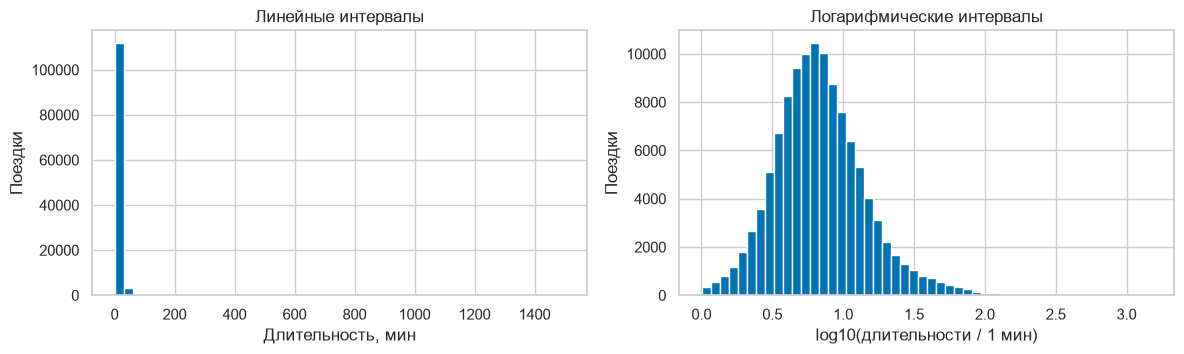

In [5]:
duration = df.duration_min[df.duration_min.gt(0)]
display(duration.describe(percentiles=[.01, .5, .95, .99]))
display(df.loc[df.duration_min.gt(1440), ["ride_id", "started_at", "ended_at", "duration_min"]].head())
q1, q3 = duration.quantile([.25, .75])
flagged = duration.gt(q3 + 1.5 * (q3 - q1))
display(pd.Series({"IQR upper": q3 + 1.5 * (q3-q1), "flagged": flagged.sum(),
                   "share of recorded minutes": duration[flagged].sum()/duration.sum()}))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
axes[0].hist(duration, bins=50)
axes[0].set(xlabel="Длительность, мин", ylabel="Поездки", title="Линейные интервалы")
axes[1].hist(np.log10(duration), bins=50)
axes[1].set(xlabel="log10(длительности / 1 мин)", ylabel="Поездки", title="Логарифмические интервалы")
fig.tight_layout()
plt.show()

## 6. Сравнение групп

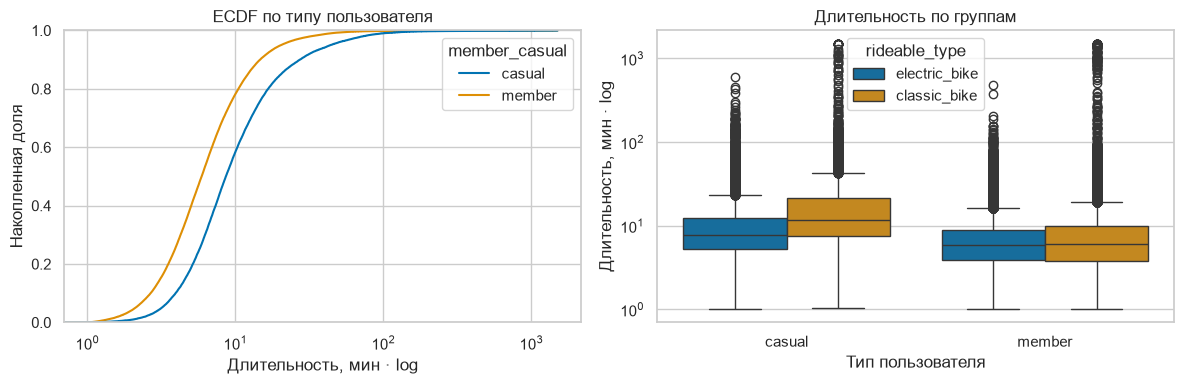

size     median       mean
member_casual rideable_type                             
casual        classic_bike    7642  11.651142  25.141759
              electric_bike  20649   7.769183  11.918054
member        classic_bike   34609   6.053183  11.725612
              electric_bike  53155   5.825950   7.579175

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.ecdfplot(data=df, x="duration_min", hue="member_casual", ax=axes[0])
axes[0].set_xscale("log")
axes[0].set(xlabel="Длительность, мин · log", ylabel="Накопленная доля", title="ECDF по типу пользователя")
sns.boxplot(data=df, x="member_casual", y="duration_min", hue="rideable_type", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set(xlabel="Тип пользователя", ylabel="Длительность, мин · log", title="Длительность по группам")
fig.tight_layout()
plt.show()
display(df.groupby(["member_casual", "rideable_type"]).duration_min.agg(["size", "median", "mean"]))

## 7. Нормировка по времени

In [7]:
days = calendar.day_type.value_counts()
comparison = df.day_type.value_counts().rename("trips").to_frame()
comparison["days"] = days
comparison["trips_per_day"] = comparison.trips / comparison.days
display(comparison)
hourly = (df.groupby(["day_type", "hour"]).size()
          .reindex(pd.MultiIndex.from_product([days.index, range(24)], names=["day_type", "hour"]), fill_value=0)
          .rename("trips").reset_index())
hourly["trips_per_day"] = hourly.trips / hourly.day_type.map(days)
fig = px.line(hourly.sort_values("hour"), x="hour", y="trips_per_day", color="day_type",
              labels={"hour": "Час старта, время файла", "trips_per_day": "Поездки / день", "day_type": "Тип дня"},
              title="Часовой профиль · сентябрь 2025")
fig.show()

,trips,days,trips_per_day
day_type,,,
Будни,86558,22,3934.454545
Выходные,29497,8,3687.125000


## 8. Координаты

In [8]:
display(df[["start_lat", "start_lng", "end_lat", "end_lng"]].describe())
valid_start = (df.start_lat.between(-90, 90) & df.start_lng.between(-180, 180)
               & ~((df.start_lat == 0) & (df.start_lng == 0)))
local_start = df.start_lat.between(40.69, 40.77) & df.start_lng.between(-74.11, -74.01)
display(pd.Series({"invalid_start": (~valid_start).sum(), "outside_local_window": (~local_start).sum()}))
sample = df.loc[valid_start].sample(5000, random_state=42)
fig = px.scatter_map(sample, lat="start_lat", lon="start_lng", opacity=.35,
                     center={"lat": 40.73, "lon": -74.045}, zoom=11.8,
                     map_style="carto-positron", title="Начала поездок · случайная выборка n=5000")
fig.show()

,start_lat,start_lng,end_lat,end_lng
count,116055.000000,116055.000000,115568.000000,115568.000000
mean,40.731920,-74.040784,40.731921,-74.040494
std,0.012288,0.012589,0.012377,0.012795
min,40.704503,-74.093680,40.668132,-74.093680
25%,40.721124,-74.046305,40.721124,-74.045953
50%,40.734961,-74.038051,40.734961,-74.037977
75%,40.742258,-74.030970,40.742258,-74.030970
max,40.754530,-74.024020,40.886300,-73.887810


invalid_start           0
outside_local_window    0
dtype: int64

## 9. Агрегация по станциям

In [9]:
stations = (df.groupby("start_station_id").agg(
    trips=("ride_id", "size"), lat=("start_lat", "median"), lon=("start_lng", "median"),
    name=("start_station_name", "first")).reset_index())
assert stations.trips.sum() == len(df)
fig = px.scatter_map(stations, lat="lat", lon="lon", size="trips", size_max=40,
                     color="trips", hover_name="name", map_style="carto-positron",
                     center={"lat": 40.73, "lon": -74.045}, zoom=11.8,
                     title="Отправления по станциям · площадь круга ∝ числу поездок")
fig.show()
display(stations.nlargest(10, "trips"))

,start_station_id,trips,lat,lon,name
81,JC115,5036,40.719410,-74.043090,Grove St PATH
3,HB106,3996,40.736722,-74.029007,River St & Newark St
0,HB101,3073,40.735938,-74.030305,Hoboken Terminal - Hudson St & Hudson Pl
34,JC009,2621,40.727596,-74.044247,Hamilton Park
26,HB609,2441,40.737215,-74.028865,River St & 1 St
5,HB202,2336,40.752961,-74.024353,14 St Ferry - 14 St & Shipyard Ln
82,JC116,2328,40.716366,-74.034344,Exchange Pl
56,JC066,2317,40.727224,-74.033759,Newport PATH
19,HB502,2225,40.749985,-74.027150,11 St & Washington St
18,HB501,2154,40.748161,-74.032453,Columbus Park - Clinton St & 9 St


## 10. Индексация H3

In [10]:
resolution = 9
df["h3"] = [h3.latlng_to_cell(lat, lon, resolution) for lat, lon in zip(df.start_lat, df.start_lng)]
cells = (df.groupby("h3").agg(starts=("ride_id", "size"), median_min=("duration_min", "median"),
                             n_duration=("duration_min", "count"), stations=("start_station_id", "nunique"))
         .reset_index().rename(columns={"h3": "cell"}))
assert cells.starts.sum() == len(df)
display(cells.head())
cell = cells.loc[cells.starts.idxmax(), "cell"]
display(cell, h3.cell_to_latlng(cell), h3.cell_area(cell, "km^2"))

,cell,starts,median_min,n_duration,stations
0,892a1070033ffff,187,11.461917,187,1
1,892a1070037ffff,51,11.176567,51,1
2,892a10700a7ffff,132,9.856600,132,1
3,892a10700abffff,268,11.684058,268,1
4,892a107011bffff,31,13.117350,31,1


'892a107216bffff'

(40.73549756593996, -74.03009461989384)

0.10586701267580613

## 11. Геометрия ячеек

In [11]:
features = []
for cell_id in cells.cell:
    ring = [[lon, lat] for lat, lon in h3.cell_to_boundary(cell_id)]
    ring.append(ring[0])
    features.append({"type": "Feature", "id": cell_id, "properties": {},
                     "geometry": {"type": "Polygon", "coordinates": [ring]}})
geojson = {"type": "FeatureCollection", "features": features}
fig = px.choropleth_map(cells, geojson=geojson, locations="cell", featureidkey="id", color="starts",
                        color_continuous_scale="Viridis", opacity=.72,
                        center={"lat": 40.73, "lon": -74.045}, zoom=11.8, map_style="carto-positron",
                        hover_data=["stations", "median_min"], title="Отправления · H3 r9")
fig.show()

## 12. Разрешение H3

In [12]:
resolution_tables = {}
for res in [7, 8, 9, 10]:
    indices = [h3.latlng_to_cell(lat, lon, res) for lat, lon in zip(df.start_lat, df.start_lng)]
    table = pd.Series(indices).value_counts().rename_axis("cell").reset_index(name="starts")
    resolution_tables[res] = table
display(pd.DataFrame([
    {"resolution": res, "cells": len(table), "max_starts": table.starts.max(),
     "min_starts": table.starts.min(), "average_hexagon_km2": h3.average_hexagon_area(res, "km^2")}
    for res, table in resolution_tables.items()]))
for res in [8, 10]:
    hex_map(resolution_tables[res], title=f"Отправления · H3 r{res} · собственная шкала").show()

,resolution,cells,max_starts,min_starts,average_hexagon_km2
0,7,9,33533,699,5.161293
1,8,32,16552,31,0.737328
2,9,80,8832,31,0.105333
3,10,94,5036,31,0.015048


## 13. Нормировка по площади

In [13]:
cells["area_km2"] = cells.cell.map(lambda value: h3.cell_area(value, "km^2"))
cells["starts_per_km2"] = cells.starts / cells.area_km2
cells["starts_per_observed_station"] = cells.starts / cells.stations
display(cells[["cell", "starts", "area_km2", "starts_per_km2", "stations", "starts_per_observed_station"]].head())
hex_map(cells, "starts_per_km2", "Отправления / км² полной ячейки · H3 r9").show()

,cell,starts,area_km2,starts_per_km2,stations,starts_per_observed_station
0,892a1070033ffff,187,0.105834,1766.918669,1,187.0
1,892a1070037ffff,51,0.105829,481.911518,1,51.0
2,892a10700a7ffff,132,0.105833,1247.243209,1,132.0
3,892a10700abffff,268,0.105839,2532.145757,1,268.0
4,892a107011bffff,31,0.105812,292.971500,1,31.0


## 14. Размер группы

In [14]:
subset = df[df.member_casual.eq("casual") & df.date.eq(pd.Timestamp("2025-09-14"))]
small = (subset.groupby("h3").duration_min.agg(starts="size", n_duration="count", median_min="median", mean_min="mean")
         .reset_index().rename(columns={"h3": "cell"}))
display(small.sort_values("mean_min", ascending=False).head(10))
threshold = 30
reliable = small[small.n_duration.ge(threshold)]
display(pd.Series({"all_cells": len(small), "shown_cells": len(reliable)}))
hex_map(reliable, "median_min", f"Медианная длительность · casual · 14.09 · n≥{threshold}").show()

,cell,starts,n_duration,median_min,mean_min
11,892a1070523ffff,4,4,15.078658,315.840892
20,892a107056bffff,1,1,158.626783,158.626783
2,892a10700abffff,3,3,74.253150,54.214750
12,892a1070527ffff,32,32,53.601892,44.436363
45,892a1072353ffff,3,3,19.783867,40.095633
64,892a1072e2bffff,4,4,15.947858,30.987517
14,892a107052fffff,11,11,44.259117,30.740182
16,892a107054bffff,11,11,16.876367,29.928302
5,892a107019bffff,2,2,28.638342,28.638342
61,892a1072a9bffff,13,13,8.619833,27.537063


all_cells      75
shown_cells    12
dtype: int64

## 15. Иерархия и соседство

In [15]:
parent_from_r9 = df.h3.map(lambda value: h3.cell_to_parent(value, 8))
direct_r8 = pd.Series([h3.latlng_to_cell(lat, lon, 8) for lat, lon in zip(df.start_lat, df.start_lng)], index=df.index)
display(pd.Series({"different_assignments": parent_from_r9.ne(direct_r8).sum(), "rows": len(df)}))
display(df.loc[parent_from_r9.ne(direct_r8), ["start_station_name", "start_lat", "start_lng", "h3"]].head())
neighbours = h3.grid_disk(cell, 1)
display(neighbours)
neighbour_table = pd.DataFrame({"cell": neighbours, "starts": [1] * len(neighbours)})
hex_map(neighbour_table, title="Ячейка и соседи · grid_disk(k=1)").show()

different_assignments      8571
rows                     116055
dtype: int64

,start_station_name,start_lat,start_lng,h3
0,Lincoln Park,40.724605,-74.078406,892a107054bffff
6,Lincoln Park,40.724605,-74.078406,892a107054bffff
89,Pershing Field,40.742677,-74.051789,892a1072357ffff
94,4 St & Grand St,40.742258,-74.035111,892a1072387ffff
95,4 St & Grand St,40.742258,-74.035111,892a1072387ffff


['892a107216bffff',
 '892a10723b7ffff',
 '892a10723a7ffff',
 '892a1072ed3ffff',
 '892a107216fffff',
 '892a1072163ffff',
 '892a107217bffff']

## 16. Потоки событий

In [16]:
events = endpoint_events(raw, resolution=9)
morning = event_balance(events, start, stop, hours=(7, 9))
evening = event_balance(events, start, stop, hours=(17, 19))
limit = max(morning.net.abs().max(), evening.net.abs().max())
for title, table in [("07–09", morning), ("17–19", evening)]:
    hex_map(table, "net", f"Прибытия − отправления · часы {title} · время каждого события",
            color_range=[-limit, limit], signed=True).show()
display(morning.sort_values("net").head())
display(evening.sort_values("net").head())

,cell,departures,arrivals,net
88,892a10723abffff,742,393,-349
49,892a1070597ffff,571,222,-349
85,892a1072397ffff,605,264,-341
135,892a1072e5bffff,601,263,-338
48,892a1070587ffff,352,105,-247


,cell,departures,arrivals,net
49,892a107216bffff,3351,1950,-1401
104,892a1072e7bffff,2127,943,-1184
50,892a107217bffff,1552,973,-579
38,892a10705dbffff,739,370,-369
103,892a1072e77ffff,658,432,-226


## 17. Расстояния

In [17]:
df["great_circle_km"] = distance_km(df)
display(df[["duration_min", "great_circle_km"]].describe())
display(df.loc[df.great_circle_km.eq(0), ["ride_id", "start_station_name", "end_station_name", "duration_min"]].head())
sample = df.dropna(subset=["great_circle_km"]).sample(5000, random_state=42)
fig = px.scatter(sample, x="great_circle_km", y="duration_min", color="rideable_type", opacity=.3, log_y=True,
                 labels={"great_circle_km": "Расстояние между концами по сфере, км", "duration_min": "Длительность, мин"},
                 title="Расстояние между концами и длительность · n=5000")
fig.show()

,duration_min,great_circle_km
count,116055.000000,115568.000000
mean,10.744147,1.264148
std,40.678685,0.844502
min,1.006567,0.000000
25%,4.199550,0.696951
50%,6.471567,1.084572
75%,10.387975,1.628335
max,1499.948283,25.931087


,ride_id,start_station_name,end_station_name,duration_min
54,4B052E19F333590D,Hoboken Ave at Monmouth St,Hoboken Ave at Monmouth St,20.099117
55,BED6D24420BC4E9D,Hoboken Ave at Monmouth St,Hoboken Ave at Monmouth St,97.828183
56,20EEEA7A5F469232,MLK Dr & Bramhall Ave,MLK Dr & Bramhall Ave,13.235550
168,84BE79BA7C26B2D1,Claremont Ave & JFK Blvd,Claremont Ave & JFK Blvd,2.813867
201,8ABF0BAC54BBB8A8,Glenwood Ave,Glenwood Ave,1.188450


## 18. Задание 1

In [ ]:
# TODO
pass

## 19. Задание 2

In [ ]:
# TODO
pass

## 20. Задание 3

In [ ]:
# TODO
pass